# Shears — data

The section fitted in Supplementary Note 3: three horizons drawn in
`data/DisharmonicFolds.svg`. The rectangle is the section; it is mapped to
`±HALF` m, with `z` up. Each horizon is read as a polyline, resampled every
`DS` m along its length, and kept where it lies inside the section. All three
are drawn west to east, so the younger side is always to the left of the
drawing direction, overturned limbs included; the first path in the file is
the youngest.

Writes `data/disharmonic_fold.npz`: the sampled contacts and bedding (oldest
horizon first), the horizons themselves for drawing, and the evaluation grid
axis. Numpy and matplotlib only.

## Setup

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))      # publication/: figstyle
import figstyle
figstyle.apply()

DATA_DIR = Path("./data")
SVG = DATA_DIR / "DisharmonicFolds.svg"
HALF, NG = 750.0, 301                             # the section, +-HALF m, and the evaluation grid
AX = np.linspace(-HALF, HALF, NG)
DS = 1.0                                          # resampling step along each horizon (m)

## Read the SVG

A small path reader: `M`, `L`, `H`, `V`, `C`, `S`, `Q` and `Z`, absolute and
relative, with each curve segment sampled finely before resampling.

In [2]:
def parse_path(d, n_per_curve=60):
    tokens = re.findall(r"[MmLlHhVvCcSsQqZz]|-?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?", d)
    pts, cur, start, prev_ctrl, cmd, i = [], np.zeros(2), np.zeros(2), None, None, 0
    t = np.linspace(0, 1, n_per_curve)[1:, None]

    def num(k):
        return np.array([float(tokens[i + j]) for j in range(k)])

    while i < len(tokens):
        if re.match(r"[A-Za-z]", tokens[i]):
            cmd = tokens[i]
            i += 1
            if cmd in "Zz":
                pts.append(start.copy())
                cur = start.copy()
                continue
        rel, c = cmd.islower(), cmd.upper()
        base = cur if rel else np.zeros(2)
        if c == "M":
            cur = base + num(2); i += 2; start = cur.copy(); pts.append(cur.copy())
            cmd, prev_ctrl = ("l" if rel else "L"), None
        elif c == "L":
            cur = base + num(2); i += 2; pts.append(cur.copy()); prev_ctrl = None
        elif c == "H":
            cur = np.array([(cur[0] if rel else 0) + float(tokens[i]), cur[1]]); i += 1; pts.append(cur.copy()); prev_ctrl = None
        elif c == "V":
            cur = np.array([cur[0], (cur[1] if rel else 0) + float(tokens[i])]); i += 1; pts.append(cur.copy()); prev_ctrl = None
        elif c in "CS":
            if c == "C":
                v = num(6); i += 6
                c1, c2, p = base + v[:2], base + v[2:4], base + v[4:]
            else:
                v = num(4); i += 4
                c1 = 2 * cur - prev_ctrl if prev_ctrl is not None else cur.copy()   # reflected control point
                c2, p = base + v[:2], base + v[2:]
            pts.extend((1 - t) ** 3 * cur + 3 * (1 - t) ** 2 * t * c1 + 3 * (1 - t) * t ** 2 * c2 + t ** 3 * p)
            prev_ctrl, cur = c2, p
        elif c == "Q":
            v = num(4); i += 4
            c1, p = base + v[:2], base + v[2:]
            pts.extend((1 - t) ** 2 * cur + 2 * (1 - t) * t * c1 + t ** 2 * p)
            prev_ctrl, cur = None, p
        else:
            raise ValueError(f"unsupported SVG command {cmd}")
    return np.array(pts)


def resample(line, ds):
    # Even spacing along the polyline.
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(line, axis=0), axis=1))]
    t = np.arange(0.0, s[-1], ds)
    return np.c_[np.interp(t, s, line[:, 0]), np.interp(t, s, line[:, 1])]


txt = SVG.read_text()
x0, y0, w, h = (float(v) for v in re.search(
    r'<rect[^>]*x="([-\d.]+)"[^>]*y="([-\d.]+)"[^>]*width="([-\d.]+)"[^>]*height="([-\d.]+)"', txt).groups())
to_m = lambda p: np.c_[(p[:, 0] - x0) / w * 2 * HALF - HALF, HALF - (p[:, 1] - y0) / h * 2 * HALF]  # z up
drawn = [resample(to_m(parse_path(d)), DS) for d in re.findall(r'<path[^>]*\sd="([^"]+)"', txt)]
lines = drawn[::-1]                                # oldest first: the file lists the youngest first
inside = [(np.abs(l) <= HALF).all(axis=1) for l in lines]
print(f"section {w:g} x {h:g} SVG units -> {2 * HALF:.0f} m; {len(lines)} horizons, "
      f"{[int(m.sum()) for m in inside]} m inside the section")

section 243.86 x 243.86 SVG units -> 1500 m; 3 horizons, [3129, 4244, 2904] m inside the section


## Sample

`N_CONTACTS` points on each horizon, at random along the part inside the
section but weighted towards the sharp turns: a point's chance grows with the
local curvature (smoothed over `SMOOTH` m), `CURVATURE_BIAS` times more at the
sharpest turn than on a straight limb, and no two picks are closer than
`MIN_GAP` m. The bedding is taken at `N_BEDDING` of them: the normal to the
horizon, on its younger side (left of the drawing direction).

In [3]:
N_CONTACTS, N_BEDDING, MARGIN = 50, 8, 10.0       # MARGIN: keep samples this far inside the edges
CURVATURE_BIAS, SMOOTH, MIN_GAP = 20, 15.0, 15.0
rng = np.random.default_rng(1)


def curvature(l):
    # |d heading / ds|, smoothed over SMOOTH m.
    heading = np.unwrap(np.arctan2(*np.gradient(l, axis=0).T[::-1]))
    k = np.abs(np.gradient(heading)) / DS
    n = max(1, int(SMOOTH / DS))
    return np.convolve(k, np.ones(n) / n, mode="same")


def pick_points(candidates, weight, n):
    # Weighted draws without replacement, at least MIN_GAP m (in index) apart.
    chosen, p = [], weight[candidates] / weight[candidates].sum()
    for i in rng.choice(candidates, size=len(candidates), replace=False, p=p):
        if all(abs(i - j) * DS >= MIN_GAP for j in chosen):
            chosen.append(i)
        if len(chosen) == n:
            break
    return np.sort(chosen)


horizons, gp, gv = [], [], []
for l in lines:
    keep = np.nonzero((np.abs(l) <= HALF - MARGIN).all(axis=1))[0]
    k = curvature(l)
    weight = 1.0 + (CURVATURE_BIAS - 1.0) * k / k[keep].max()     # 1 on straight limbs, CURVATURE_BIAS at the sharpest turn
    idx = pick_points(keep, weight, N_CONTACTS)
    horizons.append(l[idx])
    tangent = np.gradient(l, axis=0)[idx]
    normal = np.c_[-tangent[:, 1], tangent[:, 0]]                 # left of the drawing direction
    normal /= np.linalg.norm(normal, axis=1, keepdims=True)
    pick = idx[np.linspace(0, N_CONTACTS - 1, N_BEDDING + 2).astype(int)[1:-1]]
    sel = np.searchsorted(idx, pick)
    gp.append(l[pick])
    gv.append(normal[sel])
horizons, gp, gv = np.stack(horizons), np.vstack(gp), np.vstack(gv)
print(f"{len(horizons)} horizons x {N_CONTACTS} contacts, {len(gp)} bedding readings")

3 horizons x 50 contacts, 24 bedding readings


## Draw

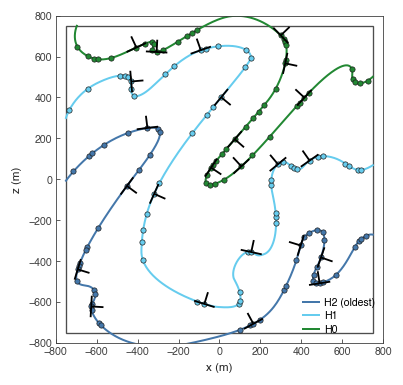

In [4]:
fig, ax = plt.subplots(figsize=(0.5 * figstyle.PRINT_WIDTH, 0.5 * figstyle.PRINT_WIDTH))
ax.add_patch(plt.Rectangle((-HALF, -HALF), 2 * HALF, 2 * HALF, fill=False, lw=0.8, color="0.3"))
for k, (l, c) in enumerate(zip(lines, figstyle.HORIZON_PALETTE)):
    ax.plot(*l.T, color=c, lw=1.2, label=f"H{len(lines) - 1 - k}" + (" (oldest)" if k == 0 else ""))
    ax.scatter(*horizons[k].T, s=10, color=c, edgecolors="0.1", linewidths=0.4, zorder=5)
figstyle.draw_younging(ax, gp, gv, color="k", quiver_scale=0.008)
ax.set_xlim(-HALF - 50, HALF + 50)
ax.set_ylim(-HALF - 50, HALF + 50)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.legend(loc="lower right", frameon=False)
plt.show()

## Save

In [5]:
np.savez(DATA_DIR / "disharmonic_fold.npz", ax=AX, horizons=horizons, gp=gp, gv=gv,
         n_lines=len(lines), **{f"line_{k}": np.where(m[:, None], l, np.nan) for k, (l, m) in enumerate(zip(lines, inside))})   # NaN: outside, so the drawn line breaks
print("wrote", DATA_DIR / "disharmonic_fold.npz")

wrote data/disharmonic_fold.npz
